### Tugas Praktikum 4: Association Rule

|     NRP      |     Nama       |
|-----------   |-------------   |
| 5054251013   | Evina Fitriyani|

### 1. Import Dataset

Dataset yang dipakai adalah Online Retail dari UCI Machine Learning Repository, berisi transaksi ritel online di Inggris dari Desember 2010 sampai Desember 2011 (541.909 baris, 8 kolom).

Data set: https://archive.ics.uci.edu/dataset/352/online+retail

In [2]:
# import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option('display.max_columns', None) # untuk melihat semua kolom saat di print
pd.set_option('display.max_colwidth', 80)

In [3]:
# import dataset Online Retail.xlsx (agak lama loadnya)

df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# cek ukuran data, harusnya 541909 baris 8 kolom

print(df.shape)

(541909, 8)


In [5]:
# cek tipe data tiap kolom dan jumlah non-null nya

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### 2. Eksplorasi dan Pembersihan Data

#### 2.1 Eksplorasi Data

Kolom yang relevan buat Association Rule adalah InvoiceNo (penanda satu transaksi) dan Description (nama produk yang dibeli). Kolom Quantity juga dicek buat nyari nilai yang nggak wajar.

In [6]:
# cek jumlah missing value tiap kolom

df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
# statistik dasar, perhatiin Quantity dan UnitPrice

df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [8]:
# simpan jumlah baris dan invoice sebelum dibersihkan

baris_awal = df.shape[0]
invoice_awal = df['InvoiceNo'].nunique()

print('Sebelum cleaning')
print('Jumlah baris   :', baris_awal)
print('Jumlah invoice :', invoice_awal)

Sebelum cleaning
Jumlah baris   : 541909
Jumlah invoice : 25900


#### 2.2 Pembersihan Data

Tahap pembersihan yang dilakukan:
- Hapus baris yang Description-nya kosong
- Hapus transaksi yang dibatalkan (InvoiceNo diawali huruf "C")
- Hapus baris dengan Quantity negatif atau nol
- Hapus baris yang bukan produk beneran (POSTAGE, Manual, dll), karena kalau dibiarkan bisa muncul di aturan dan bikin interpretasi bisnisnya aneh

In [9]:
# hapus Description kosong, invoice batal (awalan C), dan Quantity <= 0

df_clean = df.dropna(subset=['Description']).copy()
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]

print('Shape setelah cleaning:', df_clean.shape)

Shape setelah cleaning: (530693, 8)


In [10]:
# rapikan spasi di nama produk, lalu buang baris yang bukan produk

df_clean['Description'] = df_clean['Description'].str.strip()

bukan_produk = ['POSTAGE', 'Manual', 'DOTCOM POSTAGE', 'CARRIAGE', 'Discount', 'SAMPLES', 'AMAZON FEE', 'Bank Charges']
df_clean = df_clean[~df_clean['Description'].isin(bukan_produk)]

print('Shape setelah buang non-produk:', df_clean.shape)

Shape setelah buang non-produk: (528374, 8)


In [11]:
# perbandingan jumlah baris dan invoice sebelum dan sesudah cleaning

print('Sesudah cleaning')
print('Jumlah baris   :', df_clean.shape[0])
print('Jumlah invoice :', df_clean['InvoiceNo'].nunique())
print('Jumlah produk  :', df_clean['Description'].nunique())

hasil = pd.DataFrame({
    'Tahap': ['Sebelum', 'Sesudah'],
    'Jumlah Baris': [baris_awal, df_clean.shape[0]],
    'Jumlah Invoice': [invoice_awal, df_clean['InvoiceNo'].nunique()]
})
hasil

Sesudah cleaning
Jumlah baris   : 528374
Jumlah invoice : 19958
Jumlah produk  : 4058


,Tahap,Jumlah Baris,Jumlah Invoice
0,Sebelum,541909,25900
1,Sesudah,528374,19958


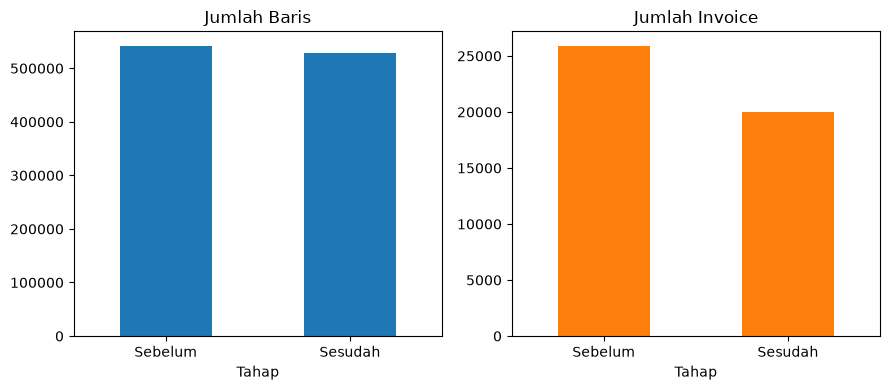

In [12]:
# visualisasi perbandingan sebelum dan sesudah cleaning

hasil.set_index('Tahap').plot(kind='bar', subplots=True, layout=(1, 2), figsize=(9, 4), legend=False, rot=0)
plt.tight_layout()
plt.show()

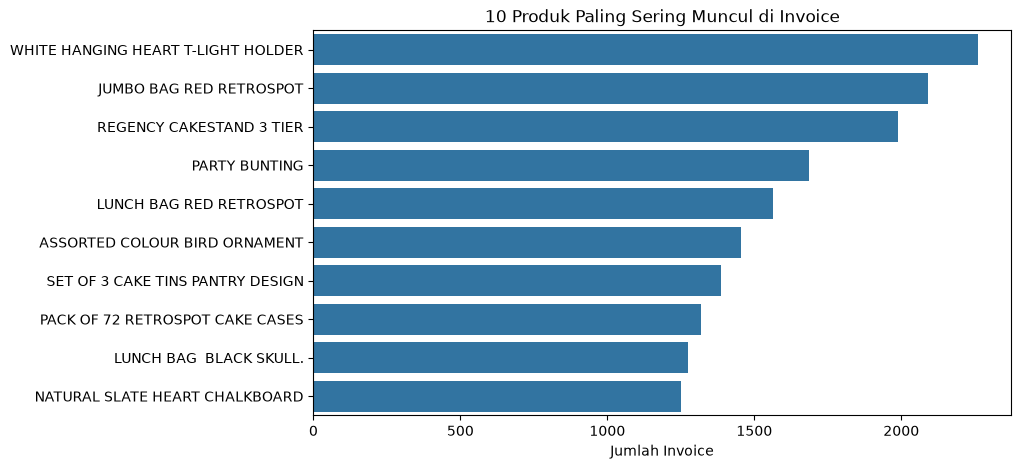

In [13]:
# 10 produk yang paling sering muncul di invoice

top_produk = df_clean.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(9,5))
sns.barplot(x=top_produk.values, y=top_produk.index)
plt.title('10 Produk Paling Sering Muncul di Invoice')
plt.xlabel('Jumlah Invoice')
plt.ylabel('')
plt.show()

count    19958.000000
mean        25.933460
std         46.827398
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max       1107.000000
Name: Description, dtype: float64


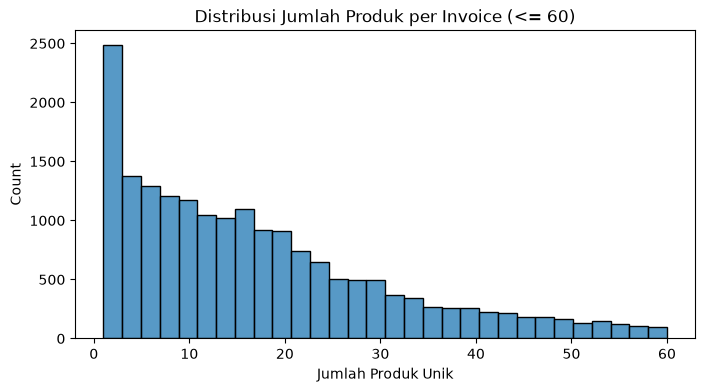

In [15]:
# distribusi jumlah produk unik per invoice

item_per_invoice = df_clean.groupby('InvoiceNo')['Description'].nunique()
print(item_per_invoice.describe())

plt.figure(figsize=(8,4))
sns.histplot(item_per_invoice[item_per_invoice <= 60], bins=30)
plt.title('Distribusi Jumlah Produk per Invoice (<= 60)')
plt.xlabel('Jumlah Produk Unik')
plt.show()

### 3. Persiapan Data untuk Association Rule

#### 3.1 Format Transaksi Berbasis Invoice

Data diubah jadi transaksi per invoice, jadi satu invoice = satu transaksi yang isinya daftar produk yang dibeli. Produk yang sama dalam satu invoice cuma dihitung sekali.

In [16]:
# bentuk transaksi per invoice, isinya list produk unik

transaksi = df_clean.groupby('InvoiceNo')['Description'].apply(lambda x: list(set(x))).tolist()

print('Jumlah transaksi:', len(transaksi))
print(transaksi[:3])

Jumlah transaksi: 19958
[['WHITE METAL LANTERN', 'RED WOOLLY HOTTIE WHITE HEART.', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'CREAM CUPID HEARTS COAT HANGER', 'SET 7 BABUSHKA NESTING BOXES', 'WHITE HANGING HEART T-LIGHT HOLDER'], ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK'], ['IVORY KNITTED MUG COSY', 'BOX OF VINTAGE ALPHABET BLOCKS', 'LOVE BUILDING BLOCK WORD', 'BOX OF VINTAGE JIGSAW BLOCKS', 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'RECIPE BOX WITH METAL HEART', "POPPY'S PLAYHOUSE BEDROOM", 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'ASSORTED COLOUR BIRD ORNAMENT', "POPPY'S PLAYHOUSE KITCHEN", 'HOME BUILDING BLOCK WORD', 'DOORMAT NEW ENGLAND']]


#### 3.2 One-Hot (Basket)

Data transaksi diubah ke bentuk one-hot pakai TransactionEncoder dari mlxtend. Tiap baris = satu invoice, tiap kolom = satu produk, nilainya True kalau produk itu ada di invoice tersebut.

In [17]:
# ubah transaksi ke bentuk one-hot

te = TransactionEncoder()
te_array = te.fit(transaksi).transform(transaksi)
basket = pd.DataFrame(te_array, columns=te.columns_)

print('Shape basket:', basket.shape)
basket.head()

Shape basket: (19958, 4058)


*Boombox Ipod Classic  *USB Office Mirror Ball  10 COLOUR SPACEBOY PEN  \
0                  False                    False                   False   
1                  False                    False                   False   
2                  False                    False                   False   
3                  False                    False                   False   
4                  False                    False                   False   

   12 COLOURED PARTY BALLOONS  12 DAISY PEGS IN WOOD BOX  \
0                       False                      False   
1                       False                      False   
2                       False                      False   
3                       False                      False   
4                       False                      False   

   12 EGG HOUSE PAINTED WOOD  12 HANGING EGGS HAND PAINTED  \
0                      False                         False   
1                      False                         False   
2                      False                         False   
3                      False                         False   
4                      False                         False   

   12 IVORY ROSE PEG PLACE SETTINGS  12 MESSAGE CARDS WITH ENVELOPES  \
0                             False                            False   
1                             False                            False   
2                             False                            False   
3                             False                            False   
4                             False                            False   

   12 PENCIL SMALL TUBE WOODLAND  12 PENCILS SMALL TUBE RED RETROSPOT  \
0                          False                                False   
1                          False                                False   
2                          False                                False   
3                          False                                False   
4                          False                                False   

   12 PENCILS SMALL TUBE SKULL  12 PENCILS TALL TUBE POSY  \
0                        False                      False   
1                        False                      False   
2                        False                      False   
3                        False                      False   
4                        False                      False   

   12 PENCILS TALL TUBE RED RETROSPOT  12 PENCILS TALL TUBE SKULLS  \
0                               False                        False   
1                               False                        False   
2                               False                        False   
3                               False                        False   
4                               False                        False   

   12 PENCILS TALL TUBE WOODLAND  12 PINK HEN+CHICKS IN BASKET  \
0                          False                         False   
1                          False                         False   
2                          False                         False   
3                          False                         False   
4                          False                         False   

   12 PINK ROSE PEG PLACE SETTINGS  12 RED ROSE PEG PLACE SETTINGS  \
0                            False                           False   
1                            False                           False   
2                            False                           False   
3                            False                           False   
4                            False                           False   

   15 PINK FLUFFY CHICKS IN BOX  15CM CHRISTMAS GLASS BALL 20 LIGHTS  \
0                         False                                False   
1                         False                                False   
2                         False                                False   
3                         False         

### 4. Penerapan Algoritma

#### 4.1 Frequent Itemset

Algoritma yang dipakai FP-Growth, dengan minimum support 0.01 sebagai titik awal. FP-Growth dipilih karena lebih cepat dari Apriori untuk data yang kolomnya banyak kayak gini.

In [18]:
# cari frequent itemset dengan min support 0.01

frequent_itemsets = fpgrowth(basket, min_support=0.01, use_colnames=True)
frequent_itemsets['panjang'] = frequent_itemsets['itemsets'].apply(len)

print('Jumlah frequent itemset:', frequent_itemsets.shape[0])
print(frequent_itemsets['panjang'].value_counts().sort_index())

Jumlah frequent itemset: 1820
panjang
1    808
2    786
3    209
4     16
5      1
Name: count, dtype: int64


In [19]:
# 10 itemset dengan support tertinggi

frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets,panjang
0,0.113238,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
92,0.104820,frozenset({JUMBO BAG RED RETROSPOT}),1
300,0.099659,frozenset({REGENCY CAKESTAND 3 TIER}),1
590,0.084477,frozenset({PARTY BUNTING}),1
41,0.078365,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.072903,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
621,0.069396,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
42,0.066139,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
174,0.063784,frozenset({LUNCH BAG BLACK SKULL.}),1
79,0.062581,frozenset({NATURAL SLATE HEART CHALKBOARD}),1


#### 4.2 Aturan Asosiasi

Aturan dibentuk dari frequent itemset dengan minimum confidence 0.5.

In [20]:
# bentuk aturan asosiasi dengan min confidence 0.5
# versi mlxtend baru butuh num_itemsets, versi lama nggak, jadi dicoba dua-duanya

try:
    rules = association_rules(frequent_itemsets, num_itemsets=len(basket), metric='confidence', min_threshold=0.5)
except TypeError:
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

print('Jumlah aturan:', rules.shape[0])
rules.head()

Jumlah aturan: 816


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({POPPY'S PLAYHOUSE BEDROOM}),frozenset({POPPY'S PLAYHOUSE KITCHEN}),0.021195,0.021846,0.015683,0.739953,33.871505,1.0,0.015220,3.761447,0.991491,0.573260,0.734145,0.728921
1,frozenset({POPPY'S PLAYHOUSE KITCHEN}),frozenset({POPPY'S PLAYHOUSE BEDROOM}),0.021846,0.021195,0.015683,0.717890,33.871505,1.0,0.015220,3.469587,0.992151,0.573260,0.711781,0.728921
2,"frozenset({JAM MAKING SET WITH JARS, SET OF 3 CAKE TINS PANTRY DESIGN})",frozenset({JAM MAKING SET PRINTED}),0.019040,0.058222,0.010322,0.542105,9.310961,1.0,0.009213,2.056756,0.909925,0.154192,0.513797,0.359693
3,"frozenset({JAM MAKING SET PRINTED, SET OF 3 CAKE TINS PANTRY DESIGN})",frozenset({JAM MAKING SET WITH JARS}),0.017387,0.056769,0.010322,0.593660,10.457427,1.0,0.009335,2.321284,0.920376,0.161695,0.569204,0.387739
4,frozenset({ALARM CLOCK BAKELIKE GREEN}),frozenset({ALARM CLOCK BAKELIKE RED}),0.049103,0.052661,0.032067,0.653061,12.401328,1.0,0.029482,2.730567,0.966838,0.460101,0.633776,0.631003


#### 4.3 Penyesuaian Nilai Support dan Confidence

Kalau aturan yang dihasilkan terlalu sedikit atau terlalu banyak, nilainya disesuaikan. Di sini dicoba beberapa kombinasi buat ngeliat jumlah aturan tiap kombinasi.

In [21]:
# coba beberapa kombinasi support dan confidence, fpgrowth cukup sekali tiap nilai support

for sup in [0.005, 0.01, 0.02]:
    fi = fpgrowth(basket, min_support=sup, use_colnames=True)
    for conf in [0.4, 0.5, 0.6]:
        if fi['itemsets'].apply(len).max() > 1:
            try:
                r = association_rules(fi, num_itemsets=len(basket), metric='confidence', min_threshold=conf)
            except TypeError:
                r = association_rules(fi, metric='confidence', min_threshold=conf)
            jumlah = r.shape[0]
        else:
            jumlah = 0
        print(f'support={sup}, confidence={conf} -> {fi.shape[0]} itemset, {jumlah} aturan')

support=0.005, confidence=0.4 -> 15301 itemset, 26586 aturan
support=0.005, confidence=0.5 -> 15301 itemset, 19585 aturan
support=0.005, confidence=0.6 -> 15301 itemset, 13422 aturan
support=0.01, confidence=0.4 -> 1820 itemset, 1193 aturan
support=0.01, confidence=0.5 -> 1820 itemset, 816 aturan
support=0.01, confidence=0.6 -> 1820 itemset, 484 aturan
support=0.02, confidence=0.4 -> 376 itemset, 117 aturan
support=0.02, confidence=0.5 -> 376 itemset, 60 aturan
support=0.02, confidence=0.6 -> 376 itemset, 30 aturan


### 5. Evaluasi Aturan Asosiasi

#### 5.1 Daftar Aturan

Aturan ditampilkan lengkap dengan nilai support, confidence, dan lift, diurutkan dari lift tertinggi.

In [23]:
# tampilkan aturan dengan support, confidence, lift (urut dari lift tertinggi)

rules_tampil = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
rules_tampil['antecedents'] = rules_tampil['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_tampil['consequents'] = rules_tampil['consequents'].apply(lambda x: ', '.join(list(x)))

rules_tampil = rules_tampil.sort_values('lift', ascending=False).reset_index(drop=True)
rules_tampil.head(20)

,antecedents,consequents,support,confidence,lift
0,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010171,0.856540,79.510823
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010171,0.944186,79.510823
2,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010171,0.953052,79.254186
3,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010171,0.845833,79.254186
4,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER BASIL",0.010021,0.833333,79.198413
5,"HERB MARKER THYME, HERB MARKER BASIL",HERB MARKER ROSEMARY,0.010021,0.952381,79.198413
6,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER BASIL",0.010021,0.843882,78.701842
7,"HERB MARKER ROSEMARY, HERB MARKER BASIL",HERB MARKER THYME,0.010021,0.934579,78.701842
8,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011073,0.932489,77.544269
9,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011073,0.920833,77.544269


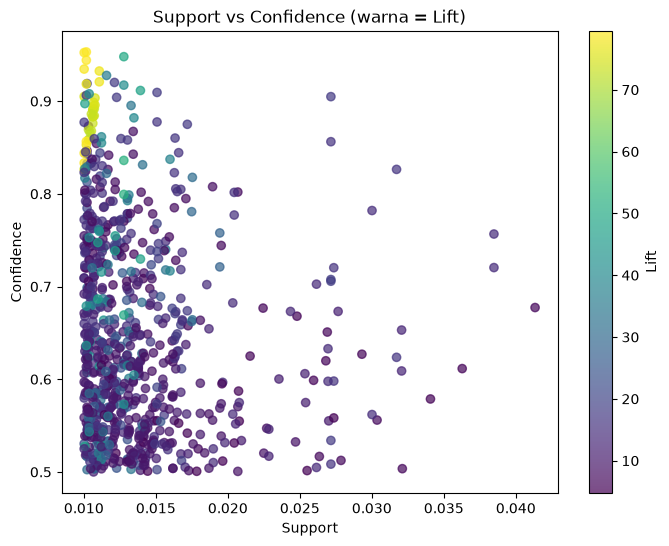

In [24]:
# visualisasi support vs confidence, warna menunjukkan lift

plt.figure(figsize=(8,6))
sc = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', alpha=0.7)
plt.colorbar(sc, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Support vs Confidence (warna = Lift)')
plt.show()

#### 5.2 Tiga Aturan Terbaik Berdasarkan Lift

Aturan A -> B dan B -> A punya lift yang sama, jadi supaya tiga aturan yang dipilih nggak kembar, diambil satu aturan untuk tiap pasangan produk.

In [22]:
# pilih 3 aturan dengan lift tertinggi (satu aturan per pasangan produk)

rules_sorted = rules.sort_values('lift', ascending=False).copy()
rules_sorted['pasangan'] = rules_sorted.apply(lambda r: frozenset(r['antecedents']) | frozenset(r['consequents']), axis=1)
top3 = rules_sorted.drop_duplicates('pasangan').head(3)

for i, (_, r) in enumerate(top3.iterrows(), 1):
    print('Aturan', i)
    print('  Jika beli  :', ', '.join(r['antecedents']))
    print('  Maka beli  :', ', '.join(r['consequents']))
    print(f"  Support    : {r['support']:.4f}")
    print(f"  Confidence : {r['confidence']:.4f}")
    print(f"  Lift       : {r['lift']:.4f}")
    print()

Aturan 1
  Jika beli  : HERB MARKER THYME
  Maka beli  : HERB MARKER PARSLEY, HERB MARKER ROSEMARY
  Support    : 0.0102
  Confidence : 0.8565
  Lift       : 79.5108

Aturan 2
  Jika beli  : HERB MARKER ROSEMARY
  Maka beli  : HERB MARKER THYME, HERB MARKER BASIL
  Support    : 0.0100
  Confidence : 0.8333
  Lift       : 79.1984

Aturan 3
  Jika beli  : HERB MARKER THYME
  Maka beli  : HERB MARKER ROSEMARY
  Support    : 0.0111
  Confidence : 0.9325
  Lift       : 77.5443



In [25]:
# tabel top 3 aturan buat laporan

top3_tabel = top3[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
top3_tabel['antecedents'] = top3_tabel['antecedents'].apply(lambda x: ', '.join(list(x)))
top3_tabel['consequents'] = top3_tabel['consequents'].apply(lambda x: ', '.join(list(x)))
top3_tabel

,antecedents,consequents,support,confidence,lift
380,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010171,0.856540,79.510823
387,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER BASIL",0.010021,0.833333,79.198413
368,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011073,0.932489,77.544269


### Ringkasan
- Dataset awal: 541909 baris, 8 kolom
- Baris dengan Description kosong, invoice batal (awalan C), dan Quantity <= 0 dibuang, begitu juga baris non-produk (POSTAGE, dll)
- Data diubah jadi transaksi per invoice, lalu ke bentuk one-hot (basket)
- Algoritma FP-Growth dengan min support 0.01 dan min confidence 0.5
- (isi sisanya setelah output keluar)